In [1]:
from pathlib import Path

required_files = [
    "X_test.npy",
    "y_test.npy",
    "basic_cnn_best.keras",
    "augmented_cnn_best.keras",
    "weighted_cnn_best.keras",
    "combined_cnn_best.keras",
    "lightweight_cnn_best.keras"
]

found_files = {}

for filename in required_files:
    matches = list(Path("/kaggle/input").rglob(filename))

    if matches:
        found_files[filename] = matches[0]
        print(f"[FOUND] {filename}")
        print(f"Path: {matches[0]}")
    else:
        print(f"[MISSING] {filename}")

print("-" * 60)
print(f"Files found: {len(found_files)}/7")

if len(found_files) == 7:
    print("STATUS: READY FOR TEST EVALUATION")
else:
    print("STATUS: RECOVERY REQUIRED")

[MISSING] X_test.npy
[MISSING] y_test.npy
[MISSING] basic_cnn_best.keras
[MISSING] augmented_cnn_best.keras
[MISSING] weighted_cnn_best.keras
[MISSING] combined_cnn_best.keras
[MISSING] lightweight_cnn_best.keras
------------------------------------------------------------
Files found: 0/7
STATUS: RECOVERY REQUIRED


In [2]:
from pathlib import Path

for path in Path("/kaggle/input").rglob("*"):
    if path.is_file():
        print(path)

/kaggle/input/datasets/yasinhossain01/saved-models/saved_models/augmented_cnn_best.keras
/kaggle/input/datasets/yasinhossain01/saved-models/saved_models/basic_cnn_best.keras
/kaggle/input/datasets/yasinhossain01/saved-models/saved_models/combined_cnn_best.keras
/kaggle/input/datasets/yasinhossain01/saved-models/saved_models/lightweight_cnn_best.keras
/kaggle/input/datasets/yasinhossain01/saved-models/saved_models/weighted_cnn_best.keras
/kaggle/input/datasets/yasinhossain01/preprocessed-dataset/preprocessed_dataset/X_test.npy
/kaggle/input/datasets/yasinhossain01/preprocessed-dataset/preprocessed_dataset/X_train.npy
/kaggle/input/datasets/yasinhossain01/preprocessed-dataset/preprocessed_dataset/X_val.npy
/kaggle/input/datasets/yasinhossain01/preprocessed-dataset/preprocessed_dataset/dataset_metadata.csv
/kaggle/input/datasets/yasinhossain01/preprocessed-dataset/preprocessed_dataset/y_test.npy
/kaggle/input/datasets/yasinhossain01/preprocessed-dataset/preprocessed_dataset/y_train.npy
/k

In [3]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/yasinhossain01/preprocessed-dataset/preprocessed_dataset"
)

MODEL_DIR = Path(
    "/kaggle/input/datasets/yasinhossain01/saved-models/saved_models"
)

# Load original test dataset
X_test = np.load(DATA_DIR / "X_test.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

# Normalize pixel values
if X_test.max() > 1:
    X_test = X_test.astype("float32") / 255.0
else:
    X_test = X_test.astype("float32")

class_names = ["Red", "Yellow", "Green"]

# Verify dataset
assert X_test.shape == (1800, 64, 64, 3)
assert len(y_test) == 1800

print("Test image shape:", X_test.shape)
print("Test label shape:", y_test.shape)
print("Total test samples:", len(X_test))
print("Pixel range:", X_test.min(), "-", X_test.max())

labels = y_test.argmax(axis=1) if y_test.ndim == 2 and y_test.shape[1] == 3 else y_test.reshape(-1)

print("\nClass Distribution:")

for i, name in enumerate(class_names):
    print(f"{name}: {np.sum(labels == i)}")

assert np.array_equal(
    np.bincount(labels.astype(int), minlength=3),
    [913, 50, 837]
)

print("\nTEST DATASET LOADED SUCCESSFULLY")

Test image shape: (1800, 64, 64, 3)
Test label shape: (1800,)
Total test samples: 1800
Pixel range: 0.0 - 1.0

Class Distribution:
Red: 913
Yellow: 50
Green: 837

TEST DATASET LOADED SUCCESSFULLY


In [4]:
import tensorflow as tf
from tensorflow import keras

model_files = {
    "EXP01_Baseline": "basic_cnn_best.keras",
    "EXP02_Augmented": "augmented_cnn_best.keras",
    "EXP03_Weighted": "weighted_cnn_best.keras",
    "EXP04_Combined": "combined_cnn_best.keras",
    "EXP05_Lightweight": "lightweight_cnn_best.keras"
}

loaded_models = {}

print("=" * 65)
print("TRAINED CNN MODEL RECOVERY")
print("=" * 65)

for name, filename in model_files.items():
    try:
        model = keras.models.load_model(
            MODEL_DIR / filename,
            compile=False
        )

        loaded_models[name] = model

        print(f"\n[SUCCESS] {name}")
        print(f"Input shape: {model.input_shape}")
        print(f"Output shape: {model.output_shape}")
        print(f"Parameters: {model.count_params():,}")

    except Exception as e:
        print(f"\n[FAILED] {name}")
        print(f"Error: {e}")

print("\n" + "=" * 65)
print(f"Models loaded: {len(loaded_models)}/5")

if len(loaded_models) == 5:
    print("STATUS: READY FOR INDEPENDENT TEST EVALUATION")

print("=" * 65)

I0000 00:00:1795560737.614689      47 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795560752.896156      47 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TRAINED CNN MODEL RECOVERY


E0000 00:00:1795560756.933418      47 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)



[SUCCESS] EXP01_Baseline
Input shape: (None, 64, 64, 3)
Output shape: (None, 3)
Parameters: 1,142,339

[SUCCESS] EXP02_Augmented
Input shape: (None, 64, 64, 3)
Output shape: (None, 3)
Parameters: 1,142,339

[SUCCESS] EXP03_Weighted
Input shape: (None, 64, 64, 3)
Output shape: (None, 3)
Parameters: 1,142,339

[SUCCESS] EXP04_Combined
Input shape: (None, 64, 64, 3)
Output shape: (None, 3)
Parameters: 1,142,339

[SUCCESS] EXP05_Lightweight
Input shape: (None, 64, 64, 3)
Output shape: (None, 3)
Parameters: 110,147

Models loaded: 5/5
STATUS: READY FOR INDEPENDENT TEST EVALUATION


In [5]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

OUTPUT_DIR = Path("/kaggle/working/independent_test_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

y_true = labels.astype(int)

test_results = []
test_predictions = {}
test_probabilities = {}

print("=" * 70)
print("INDEPENDENT TEST EVALUATION")
print("=" * 70)

assert len(loaded_models) == 5

for name, model in loaded_models.items():

    # Generate predictions without retraining
    probabilities = model.predict(
        X_test,
        batch_size=64,
        verbose=0
    )

    predictions = np.argmax(probabilities, axis=1)

    test_predictions[name] = predictions
    test_probabilities[name] = probabilities

    accuracy = accuracy_score(y_true, predictions)

    result = {
        "Model": name,
        "Test Accuracy (%)": accuracy * 100,
        "Test Loss": log_loss(
            y_true, probabilities, labels=[0, 1, 2]
        ),
        "Macro Precision": precision_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),
        "Weighted Precision": precision_score(
            y_true, predictions,
            average="weighted", zero_division=0
        ),
        "Weighted Recall": recall_score(
            y_true, predictions,
            average="weighted", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, predictions,
            average="weighted", zero_division=0
        ),
        "Correct Predictions": int(
            np.sum(y_true == predictions)
        ),
        "Incorrect Predictions": int(
            np.sum(y_true != predictions)
        ),
        "Parameters": model.count_params()
    }

    test_results.append(result)

    print(f"\n{name}")
    print(f"Accuracy: {accuracy * 100:.4f}%")
    print(f"Loss: {result['Test Loss']:.6f}")
    print(f"Macro F1: {result['Macro F1']:.6f}")
    print(f"Correct: {result['Correct Predictions']}/1800")
    print(f"Incorrect: {result['Incorrect Predictions']}")

    np.save(
        OUTPUT_DIR / f"{name}_predictions.npy",
        predictions
    )

    np.save(
        OUTPUT_DIR / f"{name}_probabilities.npy",
        probabilities
    )

test_results_df = pd.DataFrame(test_results)

test_results_df.to_csv(
    OUTPUT_DIR / "independent_test_comparison.csv",
    index=False
)

print("\n" + "=" * 70)
print("INDEPENDENT TEST EVALUATION COMPLETED")
print("=" * 70)

display(test_results_df.round(6))

INDEPENDENT TEST EVALUATION

EXP01_Baseline
Accuracy: 97.0556%
Loss: 0.141408
Macro F1: 0.864785
Correct: 1747/1800
Incorrect: 53

EXP02_Augmented
Accuracy: 96.5000%
Loss: 0.139328
Macro F1: 0.851290
Correct: 1737/1800
Incorrect: 63

EXP03_Weighted
Accuracy: 98.8889%
Loss: 0.047363
Macro F1: 0.939014
Correct: 1780/1800
Incorrect: 20

EXP04_Combined
Accuracy: 98.5000%
Loss: 0.061530
Macro F1: 0.918036
Correct: 1773/1800
Incorrect: 27

EXP05_Lightweight
Accuracy: 98.2222%
Loss: 0.103929
Macro F1: 0.944793
Correct: 1768/1800
Incorrect: 32

INDEPENDENT TEST EVALUATION COMPLETED


,Model,Test Accuracy (%),Test Loss,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Correct Predictions,Incorrect Predictions,Parameters
0,EXP01_Baseline,97.055556,0.141408,0.825553,0.942741,0.864785,0.982175,0.970556,0.974540,1747,53,1142339
1,EXP02_Augmented,96.500000,0.139328,0.811757,0.938924,0.851290,0.979914,0.965000,0.970198,1737,63,1142339
2,EXP03_Weighted,98.888889,0.047363,0.916195,0.967326,0.939014,0.990373,0.988889,0.989393,1780,20,1142339
3,EXP04_Combined,98.500000,0.061530,0.888697,0.958469,0.918036,0.988064,0.985000,0.986045,1773,27,1142339
4,EXP05_Lightweight,98.222222,0.103929,0.913348,0.987521,0.944793,0.984425,0.982222,0.982763,1768,32,110147


In [6]:
from sklearn.metrics import classification_report

all_classification_reports = []

print("=" * 70)
print("INDEPENDENT TEST CLASSIFICATION REPORTS")
print("=" * 70)

for name, predictions in test_predictions.items():

    print(f"\n{name}")
    print("-" * 65)

    report = classification_report(
        y_true,
        predictions,
        labels=[0, 1, 2],
        target_names=class_names,
        digits=6,
        zero_division=0
    )

    print(report)

    report_dict = classification_report(
        y_true,
        predictions,
        labels=[0, 1, 2],
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report_dict).transpose()

    report_df.to_csv(
        OUTPUT_DIR / f"{name}_test_classification_report.csv"
    )

    report_df = report_df.reset_index()
    report_df = report_df.rename(
        columns={"index": "Class"}
    )

    report_df.insert(0, "Model", name)

    all_classification_reports.append(report_df)

    with open(
        OUTPUT_DIR / f"{name}_test_classification_report.txt",
        "w"
    ) as f:
        f.write(report)

combined_reports = pd.concat(
    all_classification_reports,
    ignore_index=True
)

combined_reports.to_csv(
    OUTPUT_DIR / "all_test_classification_reports.csv",
    index=False
)

print("=" * 70)
print("ALL CLASSIFICATION REPORTS SAVED SUCCESSFULLY")
print("=" * 70)

INDEPENDENT TEST CLASSIFICATION REPORTS

EXP01_Baseline
-----------------------------------------------------------------
              precision    recall  f1-score   support

         Red   0.993143  0.951807  0.972036       913
      Yellow   0.483516  0.880000  0.624113        50
       Green   1.000000  0.996416  0.998205       837

    accuracy                       0.970556      1800
   macro avg   0.825553  0.942741  0.864785      1800
weighted avg   0.982175  0.970556  0.974540      1800


EXP02_Augmented
-----------------------------------------------------------------
              precision    recall  f1-score   support

         Red   0.990826  0.946331  0.968067       913
      Yellow   0.444444  0.880000  0.590604        50
       Green   1.000000  0.990442  0.995198       837

    accuracy                       0.965000      1800
   macro avg   0.811757  0.938924  0.851290      1800
weighted avg   0.979914  0.965000  0.970198      1800


EXP03_Weighted
-----------------

INDEPENDENT TEST CONFUSION MATRICES

EXP01_Baseline
        Red  Yellow  Green
Red     869      44      0
Yellow    6      44      0
Green     0       3    834


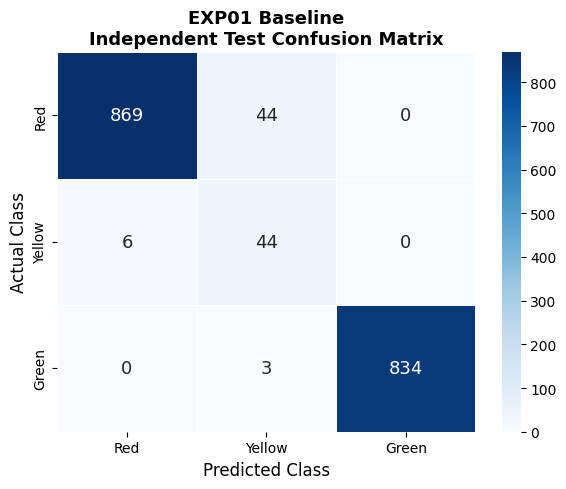


EXP02_Augmented
        Red  Yellow  Green
Red     864      49      0
Yellow    6      44      0
Green     2       6    829


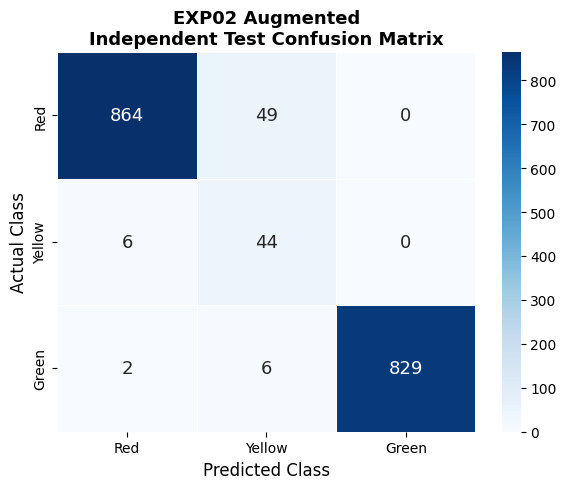


EXP03_Weighted
        Red  Yellow  Green
Red     902      11      0
Yellow    4      46      0
Green     1       4    832


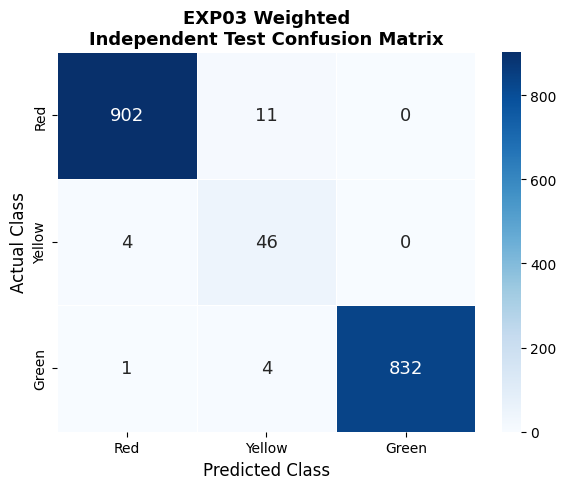


EXP04_Combined
        Red  Yellow  Green
Red     896      17      0
Yellow    5      45      0
Green     0       5    832


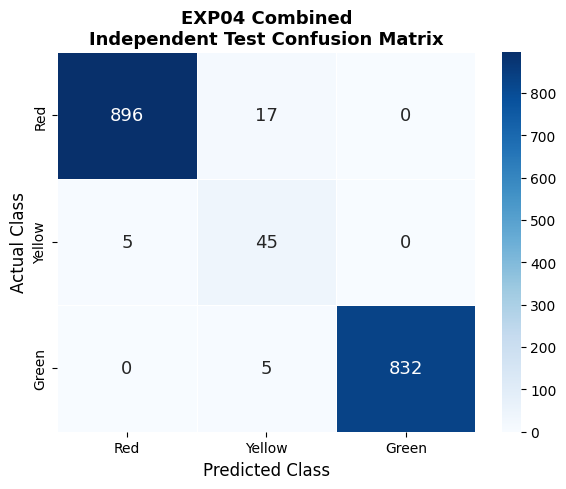


EXP05_Lightweight
        Red  Yellow  Green
Red     905       7      1
Yellow    0      50      0
Green    15       9    813


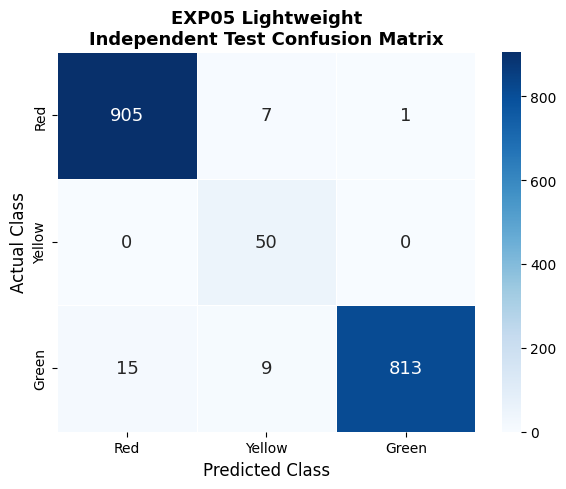


ALL CONFUSION MATRICES SAVED SUCCESSFULLY


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

confusion_matrices = {}

print("=" * 70)
print("INDEPENDENT TEST CONFUSION MATRICES")
print("=" * 70)

for name, predictions in test_predictions.items():

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1, 2]
    )

    confusion_matrices[name] = cm

    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )

    print(f"\n{name}")
    print(cm_df)

    # Save numerical confusion matrix
    cm_df.to_csv(
        OUTPUT_DIR / f"{name}_test_confusion_matrix.csv"
    )

    # Generate research figure
    fig, ax = plt.subplots(figsize=(6, 5))

    sns.heatmap(
        cm_df,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=0.5,
        annot_kws={"size": 13},
        cbar=True,
        ax=ax
    )

    ax.set_title(
        f"{name.replace('_', ' ')}\n"
        "Independent Test Confusion Matrix",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Predicted Class", fontsize=12)
    ax.set_ylabel("Actual Class", fontsize=12)

    plt.tight_layout()

    # Save high-resolution PNG
    fig.savefig(
        OUTPUT_DIR / f"{name}_test_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    # Save vector PDF
    fig.savefig(
        OUTPUT_DIR / f"{name}_test_confusion_matrix.pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("\n" + "=" * 70)
print("ALL CONFUSION MATRICES SAVED SUCCESSFULLY")
print("=" * 70)

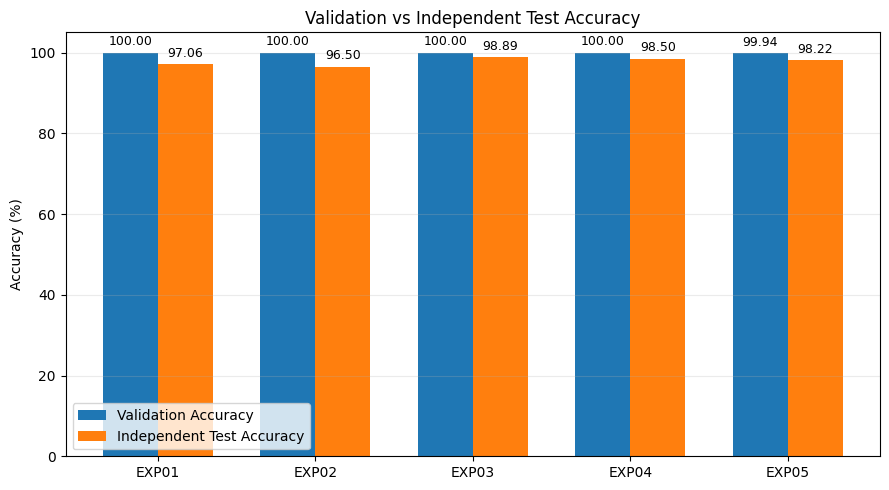

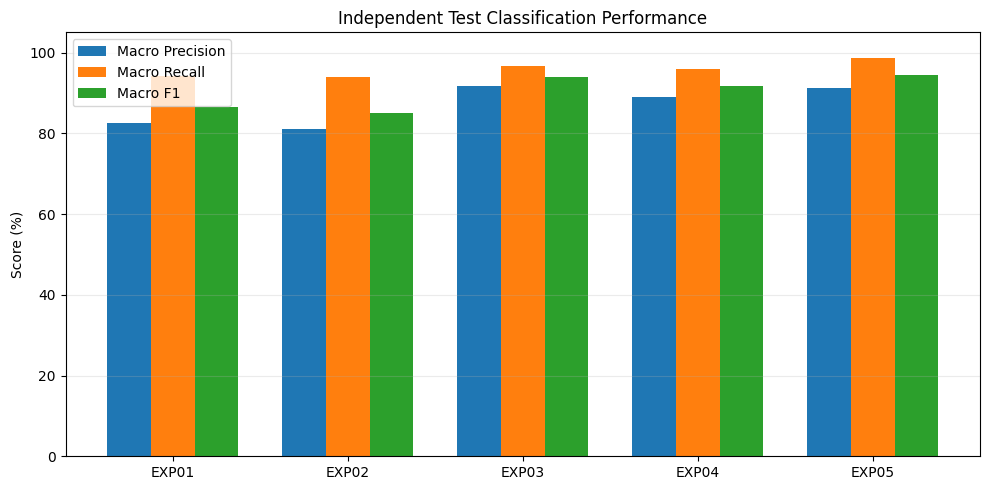

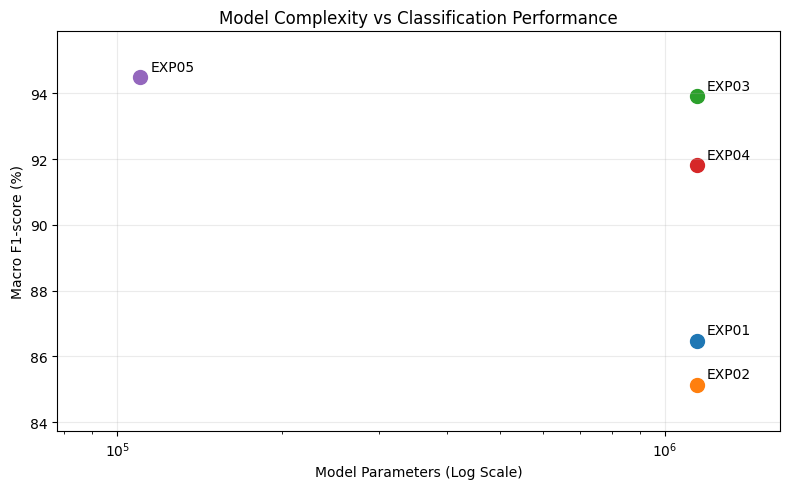

,Model,Test Accuracy (%),Test Loss,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Correct Predictions,Incorrect Predictions,Parameters,Experiment,Validation Accuracy (%),Generalization Gap (%)
0,EXP01_Baseline,97.055556,0.141408,0.825553,0.942741,0.864785,0.982175,0.970556,0.974540,1747,53,1142339,EXP01,100.000000,2.944444
1,EXP02_Augmented,96.500000,0.139328,0.811757,0.938924,0.851290,0.979914,0.965000,0.970198,1737,63,1142339,EXP02,100.000000,3.500000
2,EXP03_Weighted,98.888889,0.047363,0.916195,0.967326,0.939014,0.990373,0.988889,0.989393,1780,20,1142339,EXP03,100.000000,1.111111
3,EXP04_Combined,98.500000,0.061530,0.888697,0.958469,0.918036,0.988064,0.985000,0.986045,1773,27,1142339,EXP04,100.000000,1.500000
4,EXP05_Lightweight,98.222222,0.103929,0.913348,0.987521,0.944793,0.984425,0.982222,0.982763,1768,32,110147,EXP05,99.944444,1.722222


ALL FINAL COMPARISON FIGURES SAVED SUCCESSFULLY


In [8]:
import matplotlib.pyplot as plt
import numpy as np

comparison_df = test_results_df.copy()

comparison_df["Experiment"] = [
    "EXP01", "EXP02", "EXP03", "EXP04", "EXP05"
]

comparison_df["Validation Accuracy (%)"] = [
    100.0, 100.0, 100.0, 100.0,
    1799 / 1800 * 100
]

comparison_df["Generalization Gap (%)"] = (
    comparison_df["Validation Accuracy (%)"]
    - comparison_df["Test Accuracy (%)"]
)

comparison_df.to_csv(
    OUTPUT_DIR / "final_model_comparison.csv",
    index=False
)

x = np.arange(len(comparison_df))
width = 0.35

# Figure 1: Validation vs Test Accuracy
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    comparison_df["Validation Accuracy (%)"],
    width,
    label="Validation Accuracy"
)

ax.bar(
    x + width / 2,
    comparison_df["Test Accuracy (%)"],
    width,
    label="Independent Test Accuracy"
)

ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Experiment"])
ax.set_ylabel("Accuracy (%)")
ax.set_title("Validation vs Independent Test Accuracy")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()

for ext in ["png", "pdf"]:
    fig.savefig(
        OUTPUT_DIR / f"validation_vs_test_accuracy.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)


# Figure 2: Macro Precision, Recall and F1
fig, ax = plt.subplots(figsize=(10, 5))

width = 0.25

metrics = [
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

for i, metric in enumerate(metrics):
    ax.bar(
        x + (i - 1) * width,
        comparison_df[metric] * 100,
        width,
        label=metric
    )

ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Experiment"])
ax.set_ylabel("Score (%)")
ax.set_title("Independent Test Classification Performance")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

for ext in ["png", "pdf"]:
    fig.savefig(
        OUTPUT_DIR / f"test_metrics_comparison.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)


# Figure 3: Model Parameters vs Macro F1
fig, ax = plt.subplots(figsize=(8, 5))

for _, row in comparison_df.iterrows():

    ax.scatter(
        row["Parameters"],
        row["Macro F1"] * 100,
        s=100
    )

    ax.annotate(
        row["Experiment"],
        (
            row["Parameters"],
            row["Macro F1"] * 100
        ),
        xytext=(7, 5),
        textcoords="offset points"
    )

ax.set_xscale("log")
ax.set_xlabel("Model Parameters (Log Scale)")
ax.set_ylabel("Macro F1-score (%)")
ax.set_title("Model Complexity vs Classification Performance")
ax.grid(alpha=0.25)
ax.margins(x=0.15, y=0.15)

plt.tight_layout()

for ext in ["png", "pdf"]:
    fig.savefig(
        OUTPUT_DIR / f"complexity_vs_performance.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

display(comparison_df.round(6))

print("ALL FINAL COMPARISON FIGURES SAVED SUCCESSFULLY")

In [9]:
import shutil
import zipfile
import os

from pathlib import Path
from IPython.display import FileLink, display

# Create ZIP backup
zip_path = shutil.make_archive(
    "/kaggle/working/independent_test_results",
    "zip",
    root_dir=OUTPUT_DIR.parent,
    base_dir=OUTPUT_DIR.name
)

# Verify ZIP integrity
with zipfile.ZipFile(zip_path, "r") as archive:
    assert archive.testzip() is None
    print("Total archived files:", len(archive.namelist()))

size_mb = Path(zip_path).stat().st_size / (1024 ** 2)

print(f"ZIP size: {size_mb:.2f} MB")
print("ZIP integrity: PASSED")
print("BACKUP CREATED SUCCESSFULLY")

# Download link
os.chdir("/kaggle/working")

display(FileLink("independent_test_results.zip"))

Total archived files: 45
ZIP size: 0.90 MB
ZIP integrity: PASSED
BACKUP CREATED SUCCESSFULLY


/kaggle/working/independent_test_results.zip